Now that the selected enzyme classes are cleaned, I want to look at the proteins to help determine what type of classifier I should use. 

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

proj_path = Path.cwd().parent 

hydrolases_cleaned = pd.read_csv(proj_path / "data" / "CleanedSequences" / "HydrolasesCleaned.csv")
transferases_cleaned = pd.read_csv(proj_path / "data" / "CleanedSequences" / "TransferasesCleaned.csv")

hydrolases_sample = hydrolases_cleaned.sample(2000,random_state=42)
transferases_sample = transferases_cleaned.sample(2000,random_state=42)




With the loaded sequences

In [2]:
from Bio.SeqUtils.ProtParam import ProteinAnalysis

hydrolases_sample["AA Content"] = hydrolases_sample["Sequence"].apply(lambda x: ProteinAnalysis(x).amino_acids_percent)
transferases_sample["AA Content"] = transferases_sample["Sequence"].apply(lambda x: ProteinAnalysis(x).amino_acids_percent)

hydrolases_sample["SS Fraction"] = hydrolases_sample["Sequence"].apply(lambda x: ProteinAnalysis(x).secondary_structure_fraction())
transferases_sample["SS Fraction"] = transferases_sample["Sequence"].apply(lambda x: ProteinAnalysis(x).secondary_structure_fraction())
    
hydrolases_sample["MW"] = hydrolases_sample["Sequence"].apply(lambda x: ProteinAnalysis(x).molecular_weight())
transferases_sample["MW"] = transferases_sample["Sequence"].apply(lambda x: ProteinAnalysis(x).molecular_weight())

hydrolases_sample["Flexability"] = hydrolases_sample["Sequence"].apply(lambda x: np.mean(ProteinAnalysis(x).flexibility()))
hydrolases_sample["Flexability"] = transferases_sample["Sequence"].apply(lambda x: np.mean(ProteinAnalysis(x).flexibility()))

hydrolases_sample["GRAVY"] = hydrolases_sample["Sequence"].apply(lambda x: ProteinAnalysis(x).gravy())
transferases_sample["GRAVY"] = transferases_sample["Sequence"].apply(lambda x: ProteinAnalysis(x).gravy())

for amino_acid in "ACDEFGHIKLMNPQRSTVWY":
    hydrolases_sample[f"{amino_acid}"] = hydrolases_sample["AA Content"].apply(lambda x: x.get(amino_acid,0))
    transferases_sample[f"{amino_acid}"] = transferases_sample["AA Content"].apply(lambda x: x.get(amino_acid,0))

secondary_structures = ["Helix","Turn","Sheet"]
for feature in range(3):
    hydrolases_sample[f"{secondary_structures[feature]}"] = hydrolases_sample["SS Fraction"].apply(lambda x: x[feature])
    transferases_sample[f"{secondary_structures[feature]}"] = transferases_sample["SS Fraction"].apply(lambda x: x[feature])

print(hydrolases_sample.columns)


Index(['Unnamed: 0', 'Entry', 'Entry Name', 'Protein names', 'Organism',
       'Length', 'Sequence', 'AA Content', 'SS Fraction', 'MW', 'Flexability',
       'GRAVY', 'A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N',
       'P', 'Q', 'R', 'S', 'T', 'V', 'W', 'Y', 'Helix', 'Turn', 'Sheet'],
      dtype='object')


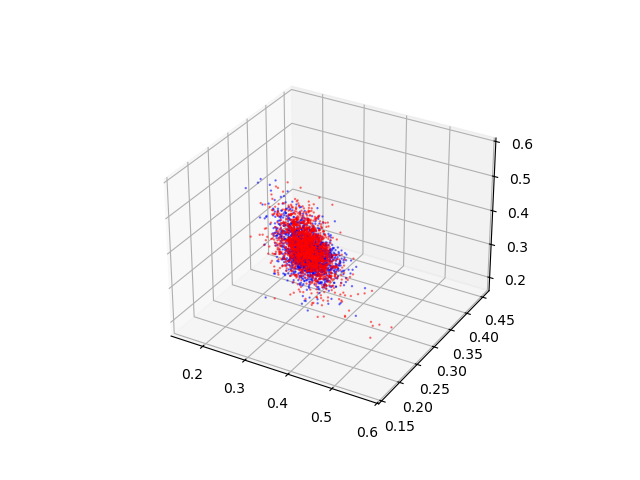

In [3]:
%matplotlib widget
import seaborn as sns 
import matplotlib.pyplot as plt


ax = plt.figure(1).add_subplot(projection="3d")
ax.scatter(hydrolases_sample["SS Fraction"].str[0],hydrolases_sample["SS Fraction"].str[1],hydrolases_sample["SS Fraction"].str[2],s=0.5,c="red",alpha=0.5)
ax.scatter(transferases_sample["SS Fraction"].str[0],transferases_sample["SS Fraction"].str[1],transferases_sample["SS Fraction"].str[2],s=0.5,c="blue",alpha=0.5)
plt.show()

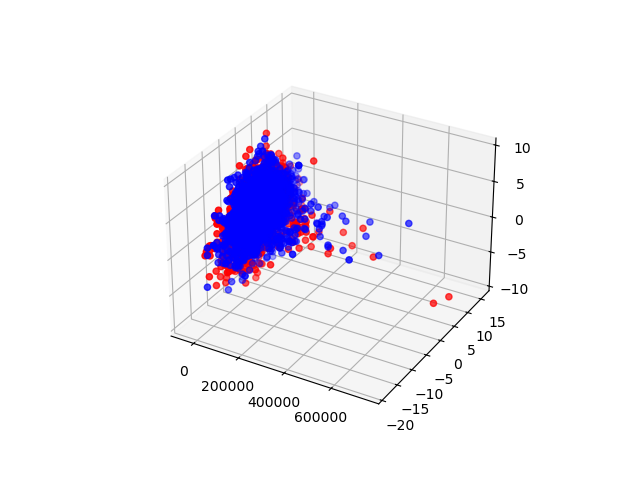

In [4]:
from sklearn.decomposition import PCA

both_classes = pd.concat([hydrolases_sample,transferases_sample])


protein_PCA = PCA(n_components=3,random_state=42).fit_transform(both_classes.iloc[:,9:].to_numpy(na_value=0))

both_classes["EC"] = ["2" for i in range(2000)] + ["3" for i in range(2000)]
both_classes["PC 1"] = protein_PCA[:,0]
both_classes["PC 2"] = protein_PCA[:,1]
both_classes["PC 3"] = protein_PCA[:,2]

ax2 = plt.figure(2).add_subplot(projection="3d")
ax2.scatter(xs="PC 1",ys="PC 2",zs="PC 3",data=both_classes.iloc[:2000,:],c="red")
ax2.scatter(xs="PC 1",ys="PC 2",zs="PC 3",data=both_classes.iloc[2000:,:],c="blue")
plt.show()

Not enough 

...


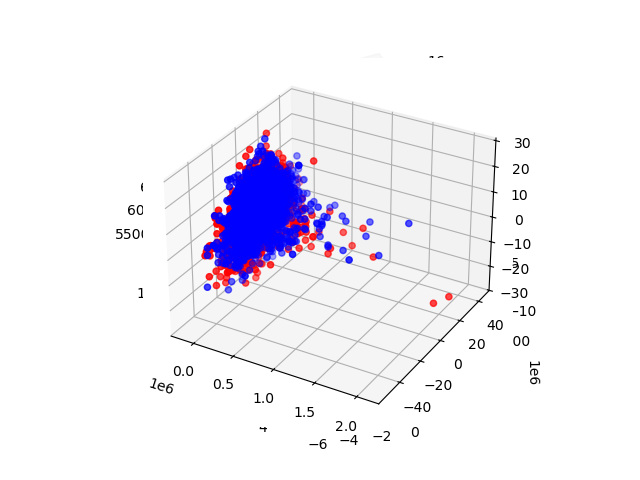

In [ ]:
from itertools import product


def kmers_freq(seq,k=3):
    kmers = ["".join(p) for p in product("ACDEFGHIKLMNPQRSTVWY",repeat=3)]
    freq = {kmer:0 for kmer in kmers}
    for i in range(len(seq) - k + 1):
        kmer = seq[i:i+k]
        if kmer in freq:
            freq[kmer] += 1
    return pd.Series([v /len(seq) for v in freq.values()])

kmers = both_classes["Sequence"].apply(kmers_freq)
kmers_pca = PCA(n_components=3,random_state=42).fit_transform(np.append(kmers.to_numpy(),both_classes.iloc[:,9:].to_numpy(na_value=0),axis=1))

both_classes["PC(kmers) 1"] = kmers_pca[:,0]
both_classes["PC(kmers) 2"] = kmers_pca[:,1]
both_classes["PC(kmers) 3"] = kmers_pca[:,2]

ax3 = plt.figure(3).add_subplot(projection="3d")
"""sns.scatterplot(both_classes,x="PC(kmers) 1",y="PC(kmers) 2")
plt.show()"""
ax3.scatter(xs="PC(kmers) 1",ys="PC(kmers) 2",zs="PC(kmers) 3",data=both_classes.iloc[:2000,:],c="red")
ax3.scatter(xs="PC(kmers) 1",ys="PC(kmers) 2",zs="PC(kmers) 3",data=both_classes.iloc[2000:,:],c="blue")
plt.show()
